# Project: Multi-Node Demand Forecaster & Inventory Optimizer
**Domain:** E-Commerce & Supply Chain Logistics  
**Dataset:** Olist Brazilian E-Commerce Public Dataset (100k+ Transactions)  

### **Business Objective**
To build a production-grade time-series forecasting engine that predicts daily product demand at the granular category level. The system is designed to optimize warehouse inventory management, prevent high-ticket stockouts, and reduce capital tied up in stagnant inventory.

### **Architectural Pipeline (Medallion Architecture)**
1. **Bronze Layer (Raw):** Ingestion of 9 highly fragmented, relational micro-service databases (orders, items, products, translations).
2. **Silver Layer (Spine):** Consolidation into a single, mathematically sound temporal spine. Includes upstream dictionary patching, semantic category consolidation (signal dilution repair), and strict data leakage amputation.
3. **Gold Layer (Matrix):** Mathematical compression of individual transactions into a daily time-series matrix, engineering target variables (`quantity`) and covariates (`freight_value`, `price`).
4. **Modeling (Future State):** Advanced Feature Engineering (Lags, Rolling Windows, Temporal encodings) feeding into an XGBoost regression model.

**Author:** Pruthvi   
**Date:** March 2026

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [16]:
raw = pd.read_csv('../data/processed/olist_cleaned_silver_spine.csv', parse_dates=['order_purchase_timestamp', 'order_date'])
df=raw.copy()

There is one nan in **order_date** while it is created using the **order_purchase_timestamp** so the data entry may be corrupted  




In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 98795 entries, 0 to 98794
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       98795 non-null  str           
 1   customer_id                    98795 non-null  str           
 2   order_purchase_timestamp       98795 non-null  datetime64[us]
 3   product_id                     98795 non-null  str           
 4   price                          98795 non-null  float64       
 5   freight_value                  98795 non-null  float64       
 6   product_category_name_english  98795 non-null  str           
 7   quantity                       98795 non-null  int64         
 8   order_date                     98795 non-null  datetime64[us]
dtypes: datetime64[us](2), float64(2), int64(1), str(4)
memory usage: 6.8 MB


In [18]:
df.head(5)

,order_id,customer_id,order_purchase_timestamp,product_id,price,freight_value,product_category_name_english,quantity,order_date
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,cool_stuff,1,2017-09-13
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,pet_shop,1,2017-04-26
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,furniture_decor,1,2018-01-14
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,7634da152a4610f1595efa32f14722fc,12.99,12.79,perfumery,1,2018-08-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,ac6c3623068f30de03045865e4e10089,199.90,18.14,garden_tools,1,2017-02-04


In [19]:
df.isna().sum()

order_id                         0
customer_id                      0
order_purchase_timestamp         0
product_id                       0
price                            0
freight_value                    0
product_category_name_english    0
quantity                         0
order_date                       0
dtype: int64

We groupby the data so that we can calculate the **quantity,avg price, avg freight values** and we removed the columns **order_id	,customer_id	order_purchase_timestamp,	product_id**	because for daily demant forcasting we don't need it

In [20]:
df_time_series = df.groupby(['order_date', 'product_category_name_english']).agg(
    daily_volume=('quantity', 'sum'),       # SUM the volume, do not count the rows
    median_price=('price', 'median'),       # MEDIAN to ignore $2,000 outliers
    median_freight=('freight_value', 'median')
).reset_index()

In [21]:
df_time_series['daily_volume'].value_counts().sample(10)

daily_volume
19      117
51        1
42        7
102       1
90        2
88        1
20      110
13      308
24       71
4      1301
Name: count, dtype: int64

In [22]:
df_time_series.isna().sum()

order_date                       0
product_category_name_english    0
daily_volume                     0
median_price                     0
median_freight                   0
dtype: int64

In [23]:
from statsmodels.tsa.stattools import adfuller

# Group the data to get the true daily heartbeat
daily_series = df_time_series.groupby('order_date')['daily_volume'].sum()

# Run the ADF statistical test
result = adfuller(daily_series)

# Print the final score
print(f"ADF Statistic: {result[0]}")
print(f"p-value: {result[1]}")

ADF Statistic: -2.9918726493622962
p-value: 0.035660395015847654


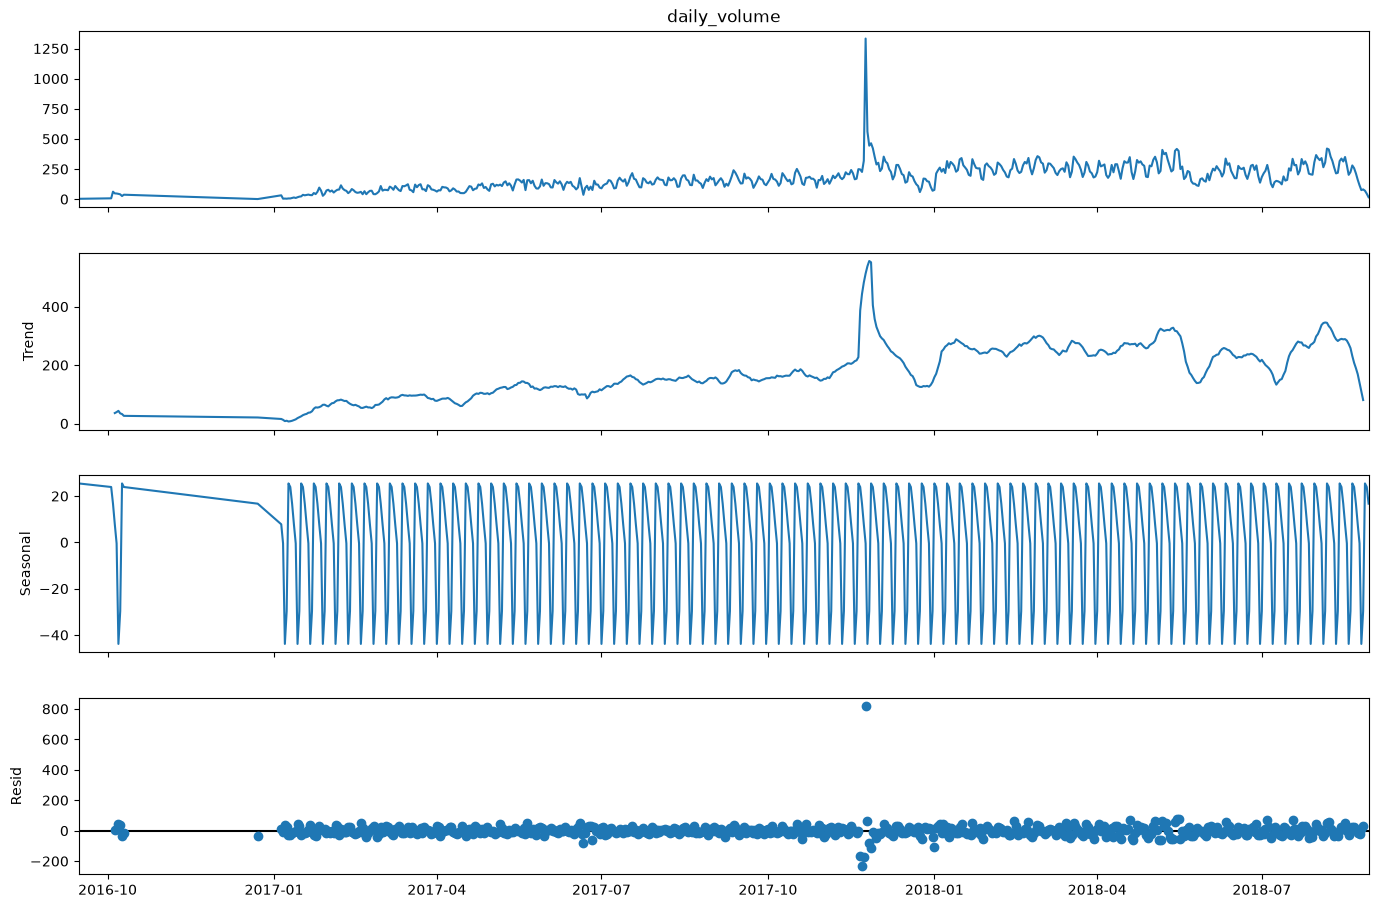

In [30]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. We must set the date as the index for the math to work
df_daily1 = daily_series.to_frame() # Convert your grouped series back to a DataFrame
df_daily1.index = pd.to_datetime(df_daily1.index)

# 2. Run the decomposition (period=7 because e-commerce runs on a 7-day weekly cycle)
decomposition = seasonal_decompose(df_daily1['daily_volume'], model='additive', period=7)

# 3. Plot the 3 hidden layers
fig = decomposition.plot()
fig.set_size_inches(15, 10)
plt.show()

In [ ]:

daily_series_clean = daily_series[daily_series.index >= '2017-01-01'].copy()

# 2. Print the confirmation
print(f"Original Timeline Start: {daily_series.index.min().date()}")
print(f"Cleaned Timeline Start: {daily_series_clean.index.min().date()}")
print(f"Total rows removed: {len(daily_series) - len(daily_series_clean)}")

Original Timeline Start: 2016-09-15
Cleaned Timeline Start: 2017-01-05
Total rows removed: 10


In [12]:
df_time_series

,order_date,product_category_name_english,daily_volume,median_price,median_freight
0,2016-09-15,health_beauty,3,44.990,2.830
1,2016-10-03,fashion_shoes,1,29.990,10.960
2,2016-10-03,furniture_decor,2,97.400,15.465
3,2016-10-03,sports_leisure,2,29.195,17.215
4,2016-10-03,toys,1,128.900,25.670
...,...,...,...,...,...
18323,2018-08-29,kitchen_dining_laundry_garden_furniture,2,209.000,46.480
18324,2018-08-29,party_supplies,1,24.900,8.330
18325,2018-08-29,sports_leisure,1,6.900,7.390
18326,2018-08-29,toys,1,63.900,9.200


In [ ]:

df_time_series = df_time_series.set_index('order_date')

df_time_series = df_time_series[df_time_series.index >= '2017-01-01']

In [28]:
df_time_series.head(2)

,product_category_name_english,daily_volume,median_price,median_freight
order_date,,,,
2017-01-05,auto,2,10.9,8.72
2017-01-05,baby,2,10.9,8.72


In [ ]:

df_daily = df_time_series.groupby('product_category_name_english')[['daily_volume', 'median_price', 'median_freight']].resample('D').asfreq()

df_daily

daily_volume  median_price  \
product_category_name_english order_date                               
agro_industry_and_commerce    2017-01-23           2.0         21.99   
                              2017-01-24           NaN           NaN   
                              2017-01-25           NaN           NaN   
                              2017-01-26           NaN           NaN   
                              2017-01-27           NaN           NaN   
...                                                ...           ...   
watches_gifts                 2018-08-25           3.0        110.65   
                              2018-08-26           2.0         93.00   
                              2018-08-27           2.0         48.50   
                              2018-08-28           1.0         59.00   
                              2018-08-29           2.0        134.40   

                                          median_freight  
product_category_name_english order_date                  
agro_industry_and_commerce    2017-01-23            8.72  
                              2017-01-24             NaN  
                              2017-01-25             NaN  
                              2017-01-26             NaN  
                              2017-01-27             NaN  
...                                                  ...  
watches_gifts                 2018-08-25           13.44  
                              2018-08-26            7.91  
                              2018-08-27            7.60  
                              2018-08-28            7.67  
                              2018-08-29            8.20  

[38837 rows x 3 columns]

In [ ]:

df_daily = df_daily.reset_index()
df_daily

,product_category_name_english,order_date,daily_volume,median_price,median_freight
0,agro_industry_and_commerce,2017-01-23,2.0,21.99,8.72
1,agro_industry_and_commerce,2017-01-24,NaN,NaN,NaN
2,agro_industry_and_commerce,2017-01-25,NaN,NaN,NaN
3,agro_industry_and_commerce,2017-01-26,NaN,NaN,NaN
4,agro_industry_and_commerce,2017-01-27,NaN,NaN,NaN
...,...,...,...,...,...
38832,watches_gifts,2018-08-25,3.0,110.65,13.44
38833,watches_gifts,2018-08-26,2.0,93.00,7.91
38834,watches_gifts,2018-08-27,2.0,48.50,7.60
38835,watches_gifts,2018-08-28,1.0,59.00,7.67


In [39]:
df_daily.shape

(38837, 5)

In [38]:
df_daily['daily_volume'].isna().sum()

np.int64(20630)

In [ ]:


df_daily['daily_volume'] = df_daily['daily_volume'].fillna(0)
df_daily['median_price'] = df_daily.groupby('product_category_name_english')['median_price'].ffill()
df_daily['median_freight'] = df_daily.groupby('product_category_name_english')['median_freight'].ffill()
print(df_daily.head())

  product_category_name_english order_date  daily_volume  median_price  \
0    agro_industry_and_commerce 2017-01-23           2.0         21.99   
1    agro_industry_and_commerce 2017-01-24           0.0         21.99   
2    agro_industry_and_commerce 2017-01-25           0.0         21.99   
3    agro_industry_and_commerce 2017-01-26           0.0         21.99   
4    agro_industry_and_commerce 2017-01-27           0.0         21.99   

   median_freight  
0            8.72  
1            8.72  
2            8.72  
3            8.72  
4            8.72  


In [ ]:

df_daily = df_daily.sort_values(by=['product_category_name_english', 'order_date'])
df_daily

,product_category_name_english,order_date,daily_volume,median_price,median_freight
0,agro_industry_and_commerce,2017-01-23,2.0,21.99,8.72
1,agro_industry_and_commerce,2017-01-24,0.0,21.99,8.72
2,agro_industry_and_commerce,2017-01-25,0.0,21.99,8.72
3,agro_industry_and_commerce,2017-01-26,0.0,21.99,8.72
4,agro_industry_and_commerce,2017-01-27,0.0,21.99,8.72
...,...,...,...,...,...
38832,watches_gifts,2018-08-25,3.0,110.65,13.44
38833,watches_gifts,2018-08-26,2.0,93.00,7.91
38834,watches_gifts,2018-08-27,2.0,48.50,7.60
38835,watches_gifts,2018-08-28,1.0,59.00,7.67


In [ ]:
df_daily.groupby('product_category_name_english')[['daily_volume','median_price']]

In [ ]:

# Look backwards: What did we sell yesterday, a week ago, and 15 days ago?
df_daily['lag_1'] = df_daily.groupby('product_category_name_english')['daily_volume'].shift(1)
df_daily['lag_7'] = df_daily.groupby('product_category_name_english')['daily_volume'].shift(7)
df_daily['lag_15'] = df_daily.groupby('product_category_name_english')['daily_volume'].shift(15)

df_daily['rolling_7_avg'] = df_daily.groupby('product_category_name_english')['lag_1'].transform(lambda x: x.rolling(window=7).mean())
df_daily['rolling_30_avg'] = df_daily.groupby('product_category_name_english')['lag_1'].transform(lambda x: x.rolling(window=30).mean())

df_daily['month'] = df_daily['order_date'].dt.month
df_daily['day_of_week'] = df_daily['order_date'].dt.dayofweek
df_daily['year'] = df_daily['order_date'].dt.year